# Transit-Gap Score per Community Area

Goal: give each of Chicago's community areas one score that shows how likely it is that rideshare is filling a gap in public transit there (issue #16).

High rideshare use alone does not mean a gap: the Loop and Near North Side have the most trips per person and the best 'L' access. A transit gap is an area where **transit access is poor**, **residents have high need**, **people still rely on rideshare**, and **their common trips need a train transfer**. The score combines these four parts.

Inputs (all from earlier notebooks):
- `results/area_population_income.csv`: population, income, hardship, trips per person, distance to the 'L', K-means cluster (notebooks 04, 05, 08)
- `results/mining/od_pairs/`: the 500 busiest origin-destination routes, 2023 onward (FP-Growth job, notebook 06)
- `data/raw/supporting/cta_L_stops.csv` and `community_areas.geojson`: which 'L' lines stop in each area

In [1]:
from pathlib import Path
import glob
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
SUP = ROOT / "data" / "raw" / "supporting"
FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

areas_df = pd.read_csv(ROOT / "results" / "area_population_income.csv")
areas_df["name"] = areas_df["name"].replace({"Ohare": "O'Hare"})
od = pd.read_csv(glob.glob(str(ROOT / "results" / "mining" / "od_pairs" / "part-*.csv"))[0])
names = areas_df.set_index("area")["name"]
print(len(areas_df), "areas,", len(od), "routes covering", f"{od['support'].sum():.0%}", "of 2023+ trips")

77 areas, 500 routes covering 78% of 2023+ trips


## 'L' lines in each area, and routes that need a transfer

In [2]:
LINES = {"RED": "Red", "BLUE": "Blue", "G": "Green", "BRN": "Brown", "P": "Purple",
         "Y": "Yellow", "PNK": "Pink", "O": "Orange"}
stops = pd.read_csv(SUP / "cta_L_stops.csv")
stops.columns = stops.columns.str.strip().str.upper()
nums = stops["LOCATION"].astype(str).str.findall(r"-?\d+\.\d+")
stops["lat"] = nums.apply(lambda v: next(float(x) for x in v if 41 < float(x) < 43))
stops["lon"] = nums.apply(lambda v: next(float(x) for x in v if -89 < float(x) < -87))
geo = gpd.read_file(SUP / "community_areas.geojson")
num_col = [c for c in geo.columns if c.lower().startswith("area_num")][0]
geo["area"] = geo[num_col].astype(float).astype(int)
pts = gpd.GeoDataFrame(stops, geometry=gpd.points_from_xy(stops["lon"], stops["lat"]), crs="EPSG:4326")
inside = gpd.sjoin(pts, geo[["area", "geometry"]].to_crs("EPSG:4326"), predicate="within")
lines = {a: {LINES[c] for c in LINES if g[c].astype(str).str.strip().str.lower().eq("true").any()}
         for a, g in inside.groupby("area")}

# A route needs a transfer when no single 'L' line stops in both areas (or either area has no station)
routes = od[od["from_area"] != od["to_area"]].copy()
routes["from_name"] = routes["from_area"].map(names)
routes["to_name"] = routes["to_area"].map(names)
routes["shared_lines"] = [", ".join(sorted(lines.get(a, set()) & lines.get(b, set())))
                          for a, b in zip(routes["from_area"], routes["to_area"])]
routes["needs_transfer"] = routes["shared_lines"] == ""
routes.to_csv(ROOT / "results" / "top_routes.csv", index=False)

transfer = (routes.groupby("from_area")
            .apply(lambda g: (g["count"] * g["needs_transfer"]).sum() / g["count"].sum(), include_groups=False)
            .rename("transfer_share"))
df = areas_df.merge(transfer, left_on="area", right_index=True, how="left")
df["has_L"] = df["area"].map(lambda a: len(lines.get(a, set())) > 0)
# Areas with none of the 500 busiest routes: every trip needs a transfer if the area has no 'L' station,
# otherwise use the city median
df["transfer_share"] = np.where(df["transfer_share"].isna() & ~df["has_L"], 1.0, df["transfer_share"])
df["transfer_share"] = df["transfer_share"].fillna(df["transfer_share"].median())
print("areas with routes in the top 500:", transfer.size, "| areas with an 'L' station:", int(df["has_L"].sum()))
df[["name", "transfer_share"]].sort_values("transfer_share", ascending=False).round(2).head(10)

areas with routes in the top 500: 55 | areas with an 'L' station: 42


,name,transfer_share
38,Kenwood,1.0
69,Ashburn,1.0
65,Chicago Lawn,1.0
64,West Lawn,1.0
35,Oakland,1.0
36,Fuller Park,1.0
1,West Ridge,1.0
39,Washington Park,1.0
40,Hyde Park,1.0
42,South Shore,1.0


## The score

Each part is standardized (z-score), so parts with different units can be added, then combined with weights and rescaled to 0–100 (100 = biggest gap). O'Hare is left out: it is an airport with about 16,000 residents, so trips per person there do not describe residents.

| Part | Measure | Weight |
| --- | --- | --- |
| Poor transit access | Distance from area center to the nearest 'L' station (km) | 0.35 |
| Need | Hardship index (2008–2012) | 0.25 |
| Reliance on rideshare | Trips per person per year, log scale | 0.20 |
| Transfer burden | Share of the area's busiest trips with no direct 'L' line | 0.20 |

In [3]:
WEIGHTS = {"dist_to_L_km": 0.35, "hardship_index": 0.25, "log_trips_pp": 0.20, "transfer_share": 0.20}
s = df[df["name"] != "O'Hare"].copy()
s["log_trips_pp"] = np.log10(s["trips_per_person_year"])
z = lambda col: (s[col] - s[col].mean()) / s[col].std()

def score(weights):
    raw = sum(w * z(c) for c, w in weights.items())
    return 100 * (raw - raw.min()) / (raw.max() - raw.min())

s["gap_score"] = score(WEIGHTS).round(1)
s["rank"] = s["gap_score"].rank(ascending=False, method="min").astype(int)
cols = ["rank", "name", "gap_score", "dist_to_L_km", "hardship_index", "trips_per_person_year", "transfer_share", "cluster"]
s.sort_values("rank")[cols].round(2).head(15)

,rank,name,gap_score,dist_to_L_km,hardship_index,trips_per_person_year,transfer_share,cluster
53,1,Riverdale,100.0,7.14,98.0,15.46,1.0,1
54,2,Hegewisch,87.4,9.44,44.0,6.07,1.0,1
45,3,South Chicago,82.4,6.13,75.0,11.39,1.0,1
50,4,South Deering,78.0,5.73,65.0,13.32,1.0,1
52,5,West Pullman,75.6,5.47,62.0,13.85,1.0,1
51,6,East Side,74.0,7.63,64.0,2.69,1.0,1
46,7,Burnside,67.0,2.41,79.0,24.49,1.0,1
18,8,Belmont Cragin,66.2,4.14,70.0,9.90,1.0,1
73,9,Mount Greenwood,65.9,8.00,16.0,4.74,1.0,1
42,10,South Shore,63.5,3.45,55.0,19.74,1.0,1


In [6]:
s.sort_values("rank")[cols].round(2).tail(10)

,rank,name,gap_score,dist_to_L_km,hardship_index,trips_per_person_year,transfer_share,cluster
31,67,Loop,22.5,0.10,3.0,173.34,0.04,0
0,68,Rogers Park,22.0,0.38,39.0,20.03,0.33,1
5,69,Lake View,20.9,0.41,5.0,56.60,0.33,0
32,69,Near South Side,20.9,0.68,7.0,66.31,0.16,0
6,71,Lincoln Park,20.6,0.38,2.0,62.58,0.32,0
2,72,Uptown,19.5,0.22,20.0,33.48,0.33,0
76,73,Edgewater,18.8,0.52,19.0,26.62,0.33,0
4,74,North Center,18.5,0.77,6.0,23.97,0.47,0
10,75,Jefferson Park,8.7,1.25,25.0,10.78,0.00,1
9,76,Norwood Park,0.0,0.56,21.0,8.21,0.00,1


The highest scores are all on the Far South Side: Riverdale (100), Hegewisch (87.4), South Chicago (82.4), South Deering (78.0) and West Pullman (75.6). These areas are 5.5–9.4 km from the nearest 'L' station, none of their busiest routes has a direct 'L' line (transfer share 1.0), and most have high hardship (Riverdale 98). All 15 top areas are in Cluster 1, the daytime, everyday cluster from K-means. A few rank high mainly because of need rather than distance: Burnside is only 2.4 km from the 'L' and Fuller Park only 0.2 km, but their hardship indexes are 79 and 97. The lowest scores are Norwood Park (0) and Jefferson Park (8.7), whose busiest trips follow the Blue Line, and the North Side lakefront and the Loop, which are close to the 'L' and have low hardship. The Loop has the most rideshare trips per person (173 per year) but still scores low, because it has every 'L' line.

## Does the ranking depend on the weights?

In [7]:
alternatives = {
    "Equal weights": {c: 0.25 for c in WEIGHTS},
    "No reliance part": {"dist_to_L_km": 0.45, "hardship_index": 0.30, "log_trips_pp": 0.0, "transfer_share": 0.25},
    "Access-heavy": {"dist_to_L_km": 0.55, "hardship_index": 0.15, "log_trips_pp": 0.15, "transfer_share": 0.15},
}
top10 = set(s.nsmallest(10, "rank")["name"])
rows = []
for label, w in alternatives.items():
    alt = score(w)
    rows.append((label, round(s["gap_score"].corr(alt, method="spearman"), 3),
                 len(top10 & set(s.loc[alt.nlargest(10).index, "name"]))))
pd.DataFrame(rows, columns=["weights", "Spearman rank correlation with ours", "same areas in top 10 (of 10)"])

,weights,Spearman rank correlation with ours,same areas in top 10 (of 10)
0,Equal weights,0.982,7
1,No reliance part,0.932,8
2,Access-heavy,0.946,7


The ranking is stable: with equal weights, without the reliance part, or with more weight on distance, the Spearman rank correlation with our ranking stays between 0.93 and 0.98, and 7–8 of our top 10 areas stay in the top 10. So the overall picture does not depend on our exact weights, but the order inside the top 10 can change, so we report the top areas as a group rather than as an exact ranking.

## Map and top areas

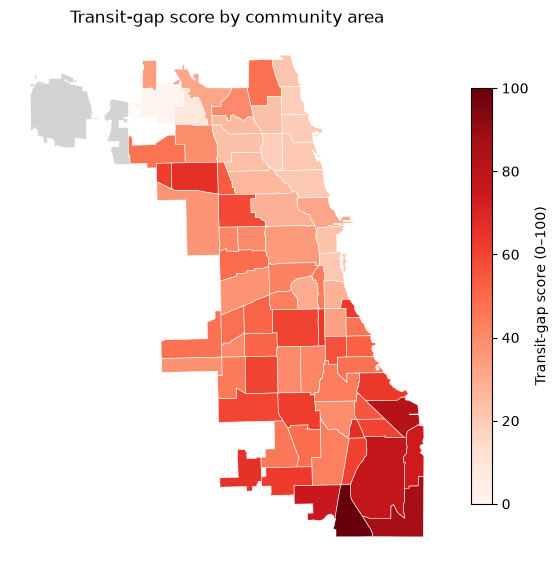

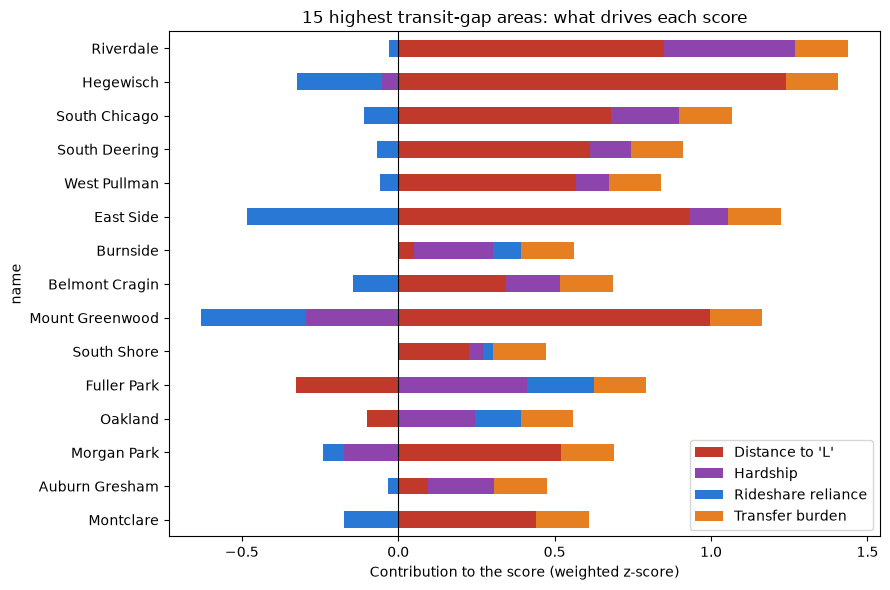

In [8]:
m = geo.merge(s[["area", "gap_score"]], on="area", how="left")
ax = m.plot(column="gap_score", cmap="Reds", legend=True, figsize=(7, 9), edgecolor="white", linewidth=0.4,
            missing_kwds={"color": "lightgrey", "label": "Not scored (O'Hare)"},
            legend_kwds={"label": "Transit-gap score (0–100)", "shrink": 0.6})
ax.set_axis_off()
ax.set_title("Transit-gap score by community area")
plt.savefig(FIGS / "transit_gap_map.png", dpi=150, bbox_inches="tight")
plt.show()

top = s.nsmallest(15, "rank").iloc[::-1]
contrib = pd.DataFrame({c: w * z(c).loc[top.index] for c, w in WEIGHTS.items()})
contrib.index = top["name"]
contrib.columns = ["Distance to 'L'", "Hardship", "Rideshare reliance", "Transfer burden"]
contrib.plot(kind="barh", stacked=True, figsize=(9, 6), color=["#c0392b", "#8e44ad", "#2a78d6", "#e67e22"])
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Contribution to the score (weighted z-score)")
plt.title("15 highest transit-gap areas: what drives each score")
plt.tight_layout()
plt.savefig(FIGS / "transit_gap_top15.png", dpi=150, bbox_inches="tight")
plt.show()

The darkest areas are on the Far South Side and the southeast lakefront, with a second, lighter group on the Northwest Side (Belmont Cragin and Montclare). The North Side lakefront and downtown are lightest. In the second chart, distance to the 'L' is the biggest part for most top areas (Riverdale, Hegewisch, East Side, Mount Greenwood), while hardship drives Burnside, Fuller Park, Oakland and Auburn Gresham. Transfer burden adds the same amount to all 15 because none of them has a direct 'L' route. Rideshare reliance is negative for most of them: residents of East Side (2.7 trips per person per year) and Mount Greenwood (4.7) use rideshare much less than the city average, so in the most cut-off areas rideshare is not filling the gap either, probably because of cost or because people drive.

## Save

In [9]:
out = df[["area", "name"]].merge(s[["area", "gap_score", "rank", "log_trips_pp"]], on="area", how="left").merge(
    df.drop(columns=["name"]), on="area")
out.drop(columns=["log_trips_pp"]).to_csv(ROOT / "results" / "transit_gap_scores.csv", index=False)
print("saved", len(out), "areas to results/transit_gap_scores.csv and", len(routes), "routes to results/top_routes.csv")

saved 77 areas to results/transit_gap_scores.csv and 448 routes to results/top_routes.csv


## What this means for the project

- We would point a transit planner first to Riverdale, South Chicago, South Deering and West Pullman: they are far from the 'L', have high hardship, and need transfers for their common trips. Burnside and Fuller Park are need-driven cases: the 'L' is close, but residents may still face cost or safety barriers.
- Low rideshare use in these areas does not mean low need. It may mean residents cannot afford rideshare and have no good transit option, which is a stronger gap than heavy rideshare use downtown.
- Limits: hardship and income are from 2008–2012; distance is measured from the area's center, not from where people live; the transfer part only uses the 500 busiest routes (78% of trips); and the weights are our choice, although the ranking stays similar when they change.